In [16]:
from tensorflow import keras
import tensorflow as tf
import numpy as np
import json
import matplotlib.pyplot as plt
import os
import sys

In [17]:
if not os.path.isdir("data"):
    print("not have train data exit!")
    sys.exit()

train_data = json.load(open('./data/train.txt', 'r'))
val_data = json.load(open('./data/val.txt', 'r'))

test_data = json.load(open('./data/test.txt', 'r'))

In [18]:
# 绘制数据集的图表
def plot_data(data):
    cos_x = [item['x'] for item in data if item['curve'] == 'cos']
    cos_y = [item['y'] for item in data if item['curve'] == 'cos']
    
    sin_x = [item['x'] for item in data if item['curve'] == 'sin']
    sin_y = [item['y'] for item in data if item['curve'] == 'sin']
    
    plt.figure(figsize=(12, 6))
    plt.plot(cos_x, cos_y, label='cos', color='blue', marker='o', linestyle='')
    plt.plot(sin_x, sin_y, label='sin', color='red', marker='x', linestyle='')
    plt.title('Cosine and Sine Curves')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()


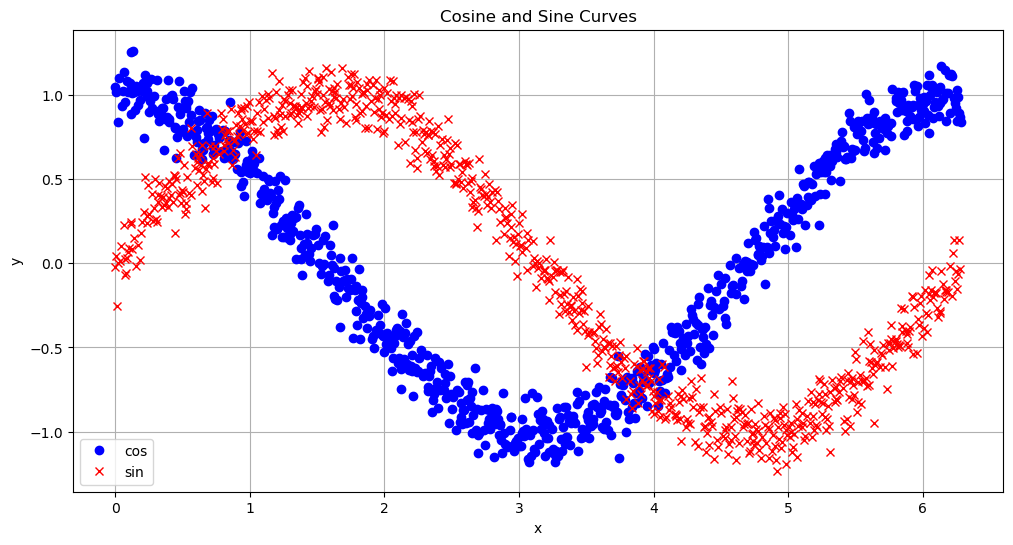

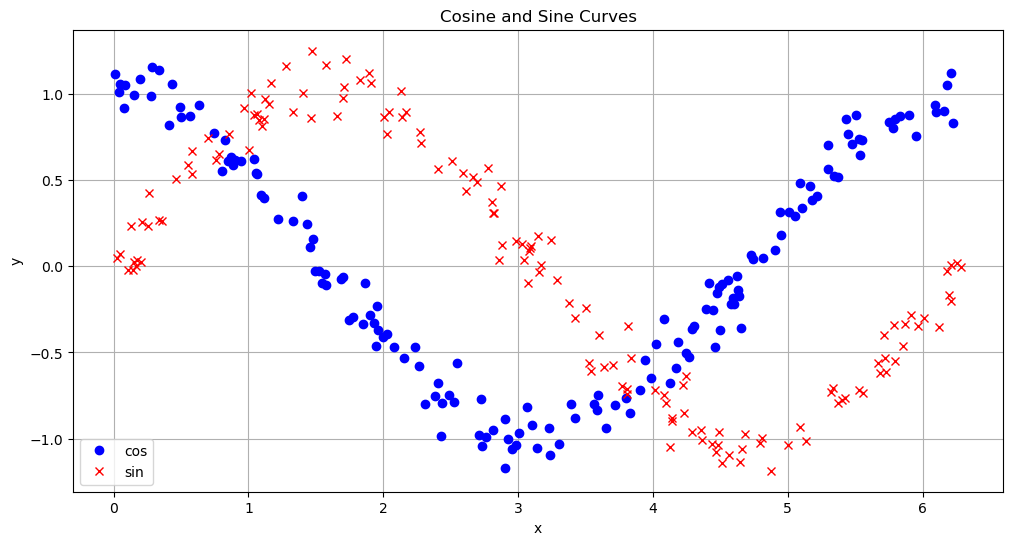

In [19]:
# 绘制训练集和验证集的图表
plot_data(train_data)
plot_data(val_data)

In [20]:
inputs = tf.keras.Input(shape=(2,))

w1 = keras.layers.Dense(16, activation='relu', input_shape=(1,), name="relu")(inputs)
w2 = keras.layers.Dense(16, activation='relu', name="relu2")(w1)
outputs = keras.layers.Dense(1, activation = 'sigmoid', name="output")(w2)

model = keras.models.Model(inputs=inputs, outputs=outputs)# type: ignore
# 编译模型
model.compile(optimizer='adam', loss='mse', metrics=['mae'])


In [21]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
relu (Dense)                 (None, 16)                48        
_________________________________________________________________
relu2 (Dense)                (None, 16)                272       
_________________________________________________________________
output (Dense)               (None, 1)                 17        
Total params: 337
Trainable params: 337
Non-trainable params: 0
_________________________________________________________________


In [22]:
def print_logo(train_x, train_y, val_x, val_y, test_x, test_y):
    print('-'*40)
    print("train data")
    print('-'*40)
    print(train_x)
    print(train_y)
    print()
    print('-'*40)
    print("val data")
    print('-'*40)
    print(val_x)
    print(val_y)
    print()
    print('-'*40)
    print("val data")
    print('-'*40)
    print(test_x)
    print(test_y)

In [23]:
# 创建标签映射字典
label_map = {'sin': 0, 'cos': 1}

# 将数据转换为numpy数组并进行适当的预处理
train_label = [label_map[item['curve']] for item in train_data]
val_label = [label_map[item['curve']] for item in val_data]
test_label = [label_map[item['curve']] for item in test_data]


# 假设train_data和val_data是包含x和y值的列表
# 将数据转换为numpy数组并进行适当的预处理
train_x = np.array([[item['x'], item['y']] for item in train_data])
# train_y = keras.utils.to_categorical(train_label, num_classes=2)
train_y = np.array(train_label)

x_validate = np.array([[item['x'], item['y']] for item in val_data])
# y_validate = keras.utils.to_categorical(val_label, num_classes=2)
y_validate = np.array(val_label)

x_test = np.array([[item['x'], item['y']] for item in test_data])
# y_test = keras.utils.to_categorical(test_label, num_classes=2)
y_test = np.array(test_label)

print_logo(train_x, train_y, x_validate, y_validate, x_test, y_test)

----------------------------------------
train data
----------------------------------------
[[ 4.40892182 -1.07751226]
 [ 3.88689542 -0.83228362]
 [ 2.9686321  -1.06603003]
 ...
 [ 0.52831588  0.92016411]
 [ 5.40894831  0.69064415]
 [ 2.25163197 -0.64006764]]
[0 0 1 ... 1 1 1]

----------------------------------------
val data
----------------------------------------
[[ 5.18252722e+00  3.81851852e-01]
 [ 4.30829023e+00 -3.47507834e-01]
 [ 1.57236870e+00 -1.09378979e-01]
 [ 2.13213195e+00  1.01384199e+00]
 [ 1.16984231e+00  1.06292927e+00]
 [ 9.68579116e-01  9.17899370e-01]
 [ 5.55360623e+00  7.32625842e-01]
 [ 1.86797401e+00 -9.49127376e-02]
 [ 5.71084310e+00 -4.00766879e-01]
 [ 1.50947395e-01  9.94668484e-01]
 [ 1.50947395e-01  2.26037763e-02]
 [ 5.94984314e+00  7.54268348e-01]
 [ 5.00642193e+00  3.12742621e-01]
 [ 1.06921071e-01 -2.30294410e-02]
 [ 4.68565871e+00 -9.71928716e-01]
 [ 4.62276396e+00 -5.85398115e-02]
 [ 3.28939531e+00 -8.08862820e-02]
 [ 1.06292124e+00  8.83190393e-01]

In [24]:
#Train the model on our training data while validating on our validation set
history = model.fit(train_x, train_y, epochs=500, batch_size=64,
                        validation_data=(x_validate, y_validate))

Epoch 1/500
25/25 [==============================] - 1s 26ms/step - loss: 0.2573 - mae: 0.4978 - val_loss: 0.2469 - val_mae: 0.4939
Epoch 2/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2444 - mae: 0.4916 - val_loss: 0.2457 - val_mae: 0.4939
Epoch 3/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2415 - mae: 0.4894 - val_loss: 0.2426 - val_mae: 0.4911
Epoch 4/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2411 - mae: 0.4896 - val_loss: 0.2401 - val_mae: 0.4883
Epoch 5/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2382 - mae: 0.4863 - val_loss: 0.2382 - val_mae: 0.4864
Epoch 6/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2361 - mae: 0.4837 - val_loss: 0.2371 - val_mae: 0.4846
Epoch 7/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2339 - mae: 0.4807 - val_loss: 0.2336 - val_mae: 0.4805
Epoch 8/500
25/25 [==============================] - 0s 2ms/step - loss: 0.2304 - 

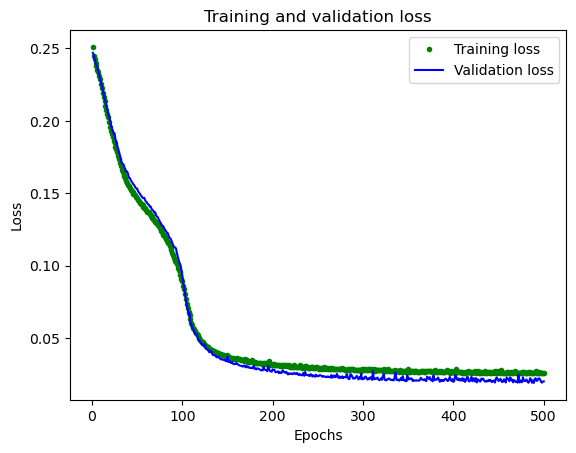

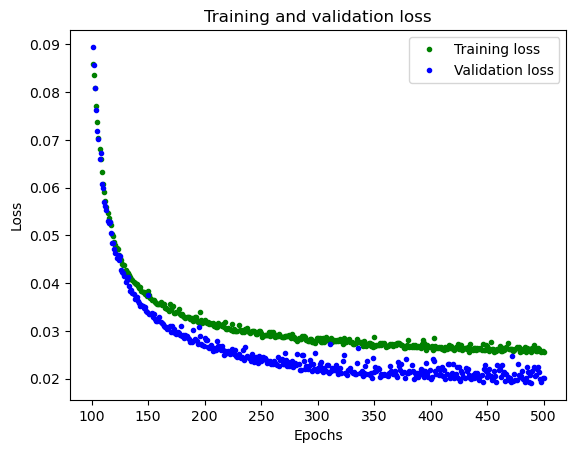

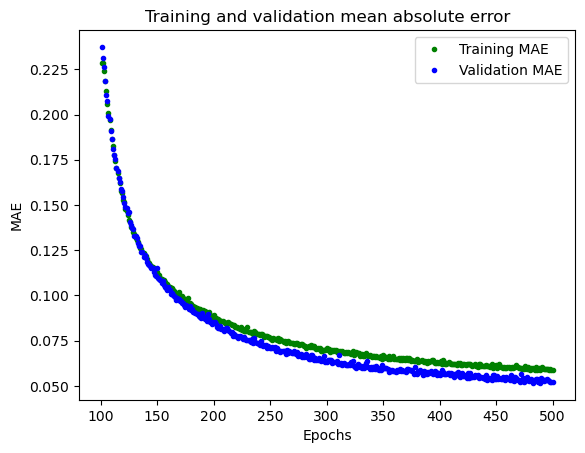

In [25]:
# Draw a graph of the loss, which is the distance between
# the predicted and actual values during training and validation.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(loss) + 1)

plt.plot(epochs, loss, 'g.', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Exclude the first few epochs so the graph is easier to read
SKIP = 100

plt.clf()

plt.plot(epochs[SKIP:], loss[SKIP:], 'g.', label='Training loss')
plt.plot(epochs[SKIP:], val_loss[SKIP:], 'b.', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.clf()

# Draw a graph of mean absolute error, which is another way of
# measuring the amount of error in the prediction.
mae = history.history['mae']
val_mae = history.history['val_mae']

plt.plot(epochs[SKIP:], mae[SKIP:], 'g.', label='Training MAE')
plt.plot(epochs[SKIP:], val_mae[SKIP:], 'b.', label='Validation MAE')
plt.title('Training and validation mean absolute error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.show()

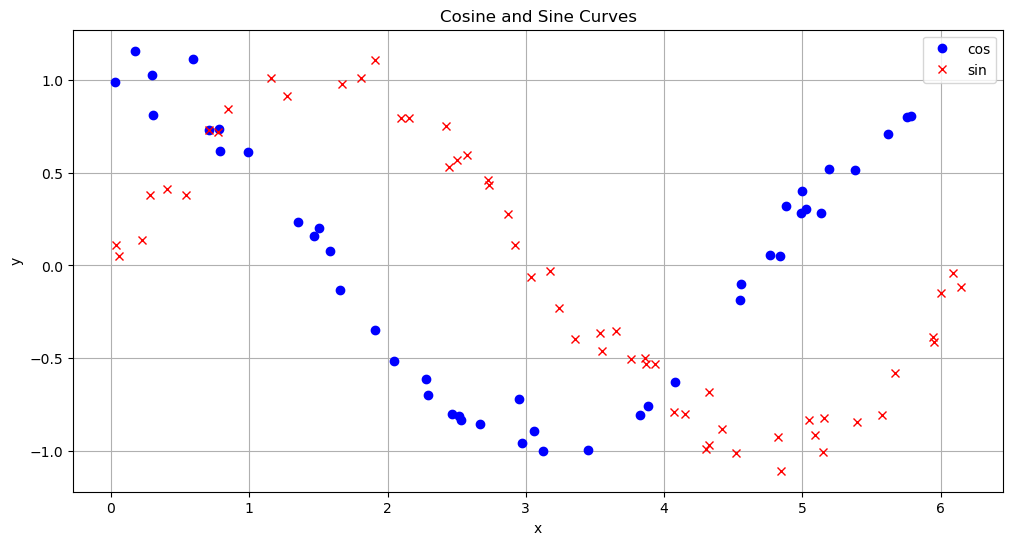

In [26]:
plot_data(test_data)

In [27]:
test_label = {'sin': 0, 'cos': 1}
test_label_num = [0] * len(test_label)

for _ in test_data:
    curve_type = _['curve']
    label_num = test_label[curve_type]
    test_label_num[label_num] += 1

print("test_label:", test_label)
print("label_num:", test_label_num)

# Calculate and print the loss on our test dataset
test_loss, test_mae = model.evaluate(x_test, y_test)

print('Test loss:', test_loss)
print('Test MAE:', test_mae)

test_label: {'sin': 0, 'cos': 1}
label_num: [56, 44]
4/4 [==============================] - 0s 679us/step - loss: 0.0269 - mae: 0.0611
Test loss: 0.026900094002485275
Test MAE: 0.06110972911119461


In [28]:
if not os.path.exists("./model"):
    os.mkdir("./model")

model.save("./model/model.h5")

In [29]:
import tensorflow as tf
import numpy as np
import os

# 确认文件是否存在
model_path = './model/model.h5'
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model file not found at: {model_path}")

# 加载整个模型
try:
    model = tf.keras.models.load_model(model_path)
except OSError as e:
    print(f"Error loading model: {e}")
    raise

# 打印模型的结构，检查层名
model.summary()

# 创建或打开一个文件来保存权重数据
with open('./model/model.txt', 'w') as f:
    for layer in model.layers:  # 直接遍历 model.layers
        # 获取层的名称
        layer_name = layer.name  # 正确访问层对象的 name 属性
        f.write(f"Layer: {layer_name}\n")
        
        # 获取层的权重
        weights = layer.get_weights()
        if weights:
            # 如果层有权重，则打印权重的形状和数据
            if len(weights) == 2:
                W, b = weights
                f.write(" Weight:\n")
                f.write(f"  Shape: {W.shape}\n")
                f.write(f"  Data: {W}\n")

                f.write(" Bias:\n")
                f.write(f"  Shape: {b.shape}\n")
                f.write(f"  Data: {b}\n")
            else:
                for i, weight in enumerate(weights):
                    f.write(f" Weight {i}:\n")
                    f.write(f"  Shape: {weight.shape}\n")
                    f.write(f"  Data: {weight}\n")
        else:
            f.write("  No weights available\n")
        f.write("\n")

print("Weights have been saved to model.txt")

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
relu (Dense)                 (None, 16)                48        
_________________________________________________________________
relu2 (Dense)                (None, 16)                272       
_________________________________________________________________
output (Dense)               (None, 1)                 17        
Total params: 337
Trainable params: 337
Non-trainable params: 0
_________________________________________________________________
Weights have been saved to model.txt


In [30]:
from tensorflow import *
import numpy as np

test_model = tf.keras.models.load_model('./model/model.h5')

test_model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
relu (Dense)                 (None, 16)                48        
_________________________________________________________________
relu2 (Dense)                (None, 16)                272       
_________________________________________________________________
output (Dense)               (None, 1)                 17        
Total params: 337
Trainable params: 337
Non-trainable params: 0
_________________________________________________________________


In [31]:
def run_model_logo(run_model_data, run_test_label: dict):
    run_test_label_num = [0] * len(run_test_label)

    for _ in run_model_data:
        curve_type = _['curve']
        label_num = run_test_label[curve_type]
        run_test_label_num[label_num] += 1

    print("test_label:", run_test_label)
    print("label_num:", run_test_label_num)

    run_model_input_y = [item['curve'] for item in run_model_data]
    run_model_input_x = np.array([[item['x'], item['y']] for item in run_model_data])
    
    print("run model input x:")
    print('-' * 40)
    print(run_model_input_x)

    return run_model_input_x, run_model_input_y, run_test_label_num


In [32]:
run_test_data = json.load(open('./data/test.txt', 'r'))
run_test_label = {'sin': 0, 'cos': 1}
run_model_input_x, run_model_input_y, run_test_label_num = run_model_logo(run_test_data, run_test_label)

test_label: {'cos': 1, 'sin': 0}
label_num: [56, 44]
run model input x:
----------------------------------------
array([[ 1.46544762,  0.16031256],
       [ 2.73592153,  0.43530235],
       [ 5.00013245,  0.40346429],
       [ 4.55357974, -0.10050192],
       [ 5.94984314, -0.41071394],
       [ 0.99373702,  0.61322159],
       [ 3.35229006, -0.39958164],
       [ 3.54726378, -0.46107173],
       [ 3.76110592, -0.50749654],
       [ 3.12586897, -1.00361073],
       [ 5.05044825, -0.83716232],
       [ 4.07557966, -0.62876886],
       [ 2.94976367, -0.7220735 ],
       [ 1.65413187, -0.13066137],
       [ 3.45292166, -0.99407059],
       [ 5.7863168 ,  0.80471307],
       [ 4.32086918, -0.6820786 ],
       [ 3.86802699, -0.53118068],
       [ 6.08821159, -0.04237077],
       [ 4.88063243,  0.31983793],
       [ 0.03144737,  0.98886275],
       [ 5.57247466, -0.80783206],
       [ 0.40881586,  0.41361457],
       [ 5.02529035,  0.30418673],
       [ 3.88689542, -0.75944674],
       [ 0.0

In [33]:

# 假设 test_data 是包含 'x', 'y' 和 'curve' 字段的列表
# run_model_input_x 是你要预测的输入数据

test_label = {'sin': 0, 'cos': 1}
label = [curve for curve in test_label]
test_prediction_rate = [0] * len(test_label) * 2


for i in range(len(run_model_input_x)):
    # 获取输入数据
    input_x = np.array([run_model_input_x[i]])
    
    # 预测输出
    output_y = test_model.predict(input_x)
    
    # 打印输入数据
    print(f"Input x: {input_x}")
    
    # 如果你有原始数据集 test_data，可以通过索引找到对应的原始标签
    original_label = test_data[i]['curve']
    predicted_label = label[int((output_y > 0.9).item())]
    
    # 打印预测结果和原始标签
    print(f"Predicted y: {output_y}")
    print(f"Original label: {original_label}")
    print(f"Predict label: {predicted_label}")
        
    if int((output_y > 0.9).item()) == test_label[[_['curve'] for _ in test_data][i]]:
        print("Correct prediction\n")
        test_prediction_rate[test_label[[_['curve'] for _ in test_data][i]]] += 1
    else:
        print("Incorrect predicti\n")
        test_prediction_rate[len(test_label) + test_label[[_['curve'] for _ in test_data][i]]] += 1



Input x: [[1.46544762 0.16031256]]
Predicted y: [[0.99156445]]
Original label: cos
Predict label: cos
Correct prediction

Input x: [[2.73592153 0.43530235]]
Predicted y: [[0.00093916]]
Original label: sin
Predict label: sin
Correct prediction

Input x: [[5.00013245 0.40346429]]
Predicted y: [[0.99981856]]
Original label: cos
Predict label: cos
Correct prediction

Input x: [[ 4.55357974 -0.10050192]]
Predicted y: [[0.99571604]]
Original label: cos
Predict label: cos
Correct prediction

Input x: [[ 5.94984314 -0.41071394]]
Predicted y: [[8.2745396e-07]]
Original label: sin
Predict label: sin
Correct prediction

Input x: [[0.99373702 0.61322159]]
Predicted y: [[0.8365997]]
Original label: cos
Predict label: sin
Incorrect predicti

Input x: [[ 3.35229006 -0.39958164]]
Predicted y: [[0.05766153]]
Original label: sin
Predict label: sin
Correct prediction

Input x: [[ 3.54726378 -0.46107173]]
Predicted y: [[0.03654128]]
Original label: sin
Predict label: sin
Correct prediction

Input x: [[ 3.

In [34]:
print('-' * 40)  
print('Accuracy of test data: ')
print(f'{test_prediction_rate}\n')

for i in range(len(test_label)):
    print('-' * 40)
    print(f'Label {label[i]} accuracy: ')
    print(f'{test_prediction_rate[i]/run_test_label_num[i]}\n')


----------------------------------------
Accuracy of test data: 
[56, 37, 0, 7]

----------------------------------------
Label sin accuracy: 
1.0

----------------------------------------
Label cos accuracy: 
0.8409090909090909



In [35]:
import tensorflow as tf
import numpy as np
import sys
import os

if not os.path.exists('./model'):
    sys.exit("Model directory not found. Please run the model_training.py script first.")

# 确认文件是否存在
model_path = './model/model.h5'
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model file not found at: {model_path}")

# 加载整个模型
try:
    model = tf.keras.models.load_model(model_path)
except OSError as e:
    print(f"Error loading model: {e}")
    raise

# 打印模型的结构，检查层名
model.summary()


Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
relu (Dense)                 (None, 16)                48        
_________________________________________________________________
relu2 (Dense)                (None, 16)                272       
_________________________________________________________________
output (Dense)               (None, 1)                 17        
Total params: 337
Trainable params: 337
Non-trainable params: 0
_________________________________________________________________


In [36]:
def read_header_file(header_file: str, model_file):
    try:
        if not os.path.exists(header_file):
            print(f"{header_file} file exists")
            return

        with open(header_file, "r") as header_file:
            for data in header_file.readlines():
                print(data.strip("\n"))
                model_file.write(data)
                
            print("\n")
            model_file.write("\n")
            header_file.close()
    except Exception  as e:
        print(e)

def save_name_header(header_file: str, model_file, type: str = "cpp"):
    read_header_file(header_file, model_file)
    if type == "cpp":
        model_file.write('#include "weight.h"\n\n')
    if type == "h":
        model_file.write("#ifndef WEIGHT_H\n")
        model_file.write("#define WEIGHT_H\n\n")

def save_model_weight(model_file, layer, W, b):
    if layer is None: return
    
    if W is None: return
    model_file.write(f"const float W_{layer.name}[] = " + "{\n")
    model_file.write("   " + str(", ".join([str(x) + "f" for x in W.flatten()])) + "\n")
    model_file.write("};\n\n")

    if b is None: return
    model_file.write(f"const float b_{layer.name}[] = " + "{\n")
    model_file.write("   " + str(", ".join([str(x) + "f" for x in b.flatten()])) + "\n")
    model_file.write("};\n\n")

In [37]:
file_type =  "cpp"

# 创建或打开一个文件来保存权重数据
with open('./model/weight.cpp', 'w') as f:

    save_name_header("header.txt", f, str(file_type))

    for layer in model.layers:
        weights = layer.get_weights()
        if weights:
            # 解包权重和偏置
            if len(weights) == 2: 
                W, b = weights
                print(f"  Weight {W.shape}")
                print(f"  Bias  {b.shape}")
                save_model_weight(f, layer, W, b)

            else:
                print(f"  Weight : {weight.shape}")
                save_model_weight(f, layer, W, None)

    if str(file_type) == "h":
        f.write("#endif")

    f.close()


print("Weights have been saved to model.cpp")

// Copyright (c) 2025. BNU-HKBU UIC RoboMaster
//
// This program is free software: you can redistribute it
// and/or modify it under the terms of the GNU General
// Public License as published by the Free Software
// Foundation, either version 3 of the License, or (at
// your option) any later version.
//
// This program is distributed in the hope that it will be
// useful, but WITHOUT ANY WARRANTY; without even
// the implied warranty of MERCHANTABILITY or FITNESS
// FOR A PARTICULAR PURPOSE.  See the GNU General
// Public License for more details.
//
// You should have received a copy of the GNU General
// Public License along with this program.  If not, see
// <https://www.gnu.org/licenses/>.


  Weight (2, 16)
  Bias  (16,)
  Weight (16, 16)
  Bias  (16,)
  Weight (16, 1)
  Bias  (1,)
Weights have been saved to model.cpp


### Next content is use to test weight.
##### by trained save to weight and make to lib file, next to deploy to stm32f1 mcu, so you can achieve Cotex-M3 with Tensorflow
##### but my is use stm32f1, so RAM is 72K, and ROM is 128K, do worry about the size of RAM
##### if you want to the ues to ArduinoUNO, that you be take care about the size of RAM and ROM, becone ArduinoUNO RAM is 2K, ROM is 32K

In [42]:
import numpy as np

W_relu = [
   -0.24149461, 0.47922814, 0.50131214, -0.4798298, -0.2532205, 0.3741976, 0.5106996, -0.5723628, 0.29312927, 0.14284667, 0.18007861, 0.53011316, 0.27659953, 0.513101, -0.35395074, 0.54553413, -0.16416028, -0.6303126, -0.4120823, 0.2846507, 0.23997353, 0.33834803, -0.31282267, -0.0821689, 0.64450747, 0.21232021, -0.21048163, 0.14289859, 0.9056437, -0.02009336, 0.5585036, 0.11996085
]

b_relu = [
   0.2994836, -1.6755055, 0.14872806, 0.18468706, 1.1543086, -0.43254453, -0.13702036, -0.016588408, -0.41021687, 0.36008996, 0.7056856, -0.47748086, -0.37318128, 0.09698134, 0.12443947, -0.033093266
]

W_relu2 = [
   -0.11274072, -0.26884854, -0.31818074, 0.6240941, 0.34621048, -2.4826257, -0.33750778, -0.12793626, 0.32733333, -0.48746654, -1.6765659, 0.09442402, -1.6495746, -0.37134352, -0.06523157, 0.196599, 0.2872597, -0.94669527, -0.4405022, 0.39935574, -0.18897972, 0.0573984, 0.13863692, -0.2820638, -0.42445695, -0.17804939, -0.34729517, -0.47730774, -0.2136918, -0.2470234, 0.40257385, -0.91330934, 0.38943264, -0.40674022, 0.061517186, -0.32632932, 0.15824439, 0.24751, 0.23129983, 0.3426468, 0.2379264, 0.23518258, -1.3227779, 0.28530386, -1.0199721, -0.3314736, 0.32155734, -0.009451947, -0.24686457, -0.44752792, 0.44205517, -0.4762933, -0.0024825886, 0.49246085, 0.07856348, -0.57931805, 0.29061812, 0.35466126, 0.41234294, 0.3665784, -0.07089147, 0.13843477, -0.34019142, -0.16569981, 0.5123804, 0.46304482, 0.15424874, 0.5077822, 0.011534924, -0.70566744, -0.029166967, 0.00042905967, 0.037140716, 0.060699154, 0.15924428, -0.4728702, 0.3066106, 0.04420945, -5.6324525, 0.08400713, -0.04175812, -0.3746421, 0.059250303, 0.12598291, 0.14477508, 0.22857308, 0.25278407, -1.7651987, -0.4251639, -0.25146306, -0.43776813, 0.089096405, -0.35222173, 0.10650184, -0.10793213, -0.18450674, 0.3170716, 0.4021158, -0.19625016, 0.19961153, 0.14310044, 0.32879505, -0.16241178, -0.40421972, -0.06590737, -0.03332301, -0.72458214, 0.26022598, -0.63882923, -0.06313098, 0.38335463, 0.38139522, -0.052731417, 0.0479196, 0.089213274, 0.045557708, -0.40378654, 0.3963642, -0.33036295, -0.024431698, 0.20503017, -0.44227433, 0.17165463, 0.12996592, -0.06749952, 0.14674279, 0.2079375, 0.20110855, 0.7082237, 0.3215022, -0.45005456, 0.66308486, -0.018726353, -0.48203918, -0.09722185, -1.1290166, 0.15686853, -0.63658667, 0.15544558, -0.5386509, 0.20366716, -0.070439056, 0.568773, 0.20577393, -0.28900704, 0.21761343, 0.1713223, -0.01243686, 0.2705438, -0.008152074, -0.26546136, 0.30531147, 0.4735157, 0.2792148, -0.10548058, 0.4089599, -0.09441017, -0.2400988, -0.041295737, -0.29637372, 0.052823853, 0.46683854, 0.018222768, -0.4375097, 0.093791105, 0.31804574, 0.16785061, 0.30490515, 0.037038468, 0.1784709, -0.21872039, 0.27974132, -0.10488409, -0.39632067, -0.4423851, 0.29102498, -0.16430871, -0.14018042, -0.46373674, 0.3474527, 0.21232437, -0.41460693, -0.41148677, -1.1273178, -0.25038847, -0.030042809, -0.58375645, -0.096017785, -1.0291692, -0.047899865, 0.20118959, -0.13664098, -0.29437074, 0.25477996, 0.63920593, -0.24880551, 0.19279757, 0.4970879, -0.28775406, 0.20165068, 0.40909508, 0.14107655, 0.40997827, 0.48870438, 0.19164604, -0.19181383, 0.93361604, 0.3333709, 0.19139722, -0.23319405, 0.30243117, 0.44087267, -0.07126297, 0.23621795, -0.18401504, -0.3844879, 0.105194, 0.28428102, -0.38414872, -0.021287136, 0.014290982, 0.31905177, -0.14982346, -0.43699184, 0.5514378, 0.43114385, -0.1313246, 0.43331885, 0.44505337, 0.26983947, -0.41944802, -0.3832314, -0.35993043, 0.007841324, 0.4314582, -0.28144726, 0.49208882, 0.26263615, -0.6908846, 0.64596707, -0.0043521724, 0.18205985, 0.049872175, 0.4354612, 0.1696114, 0.23274001, -0.2093554, 0.038454823, -0.21336825, 0.191473, 0.31857556, 0.101667956, -0.12728742, 0.07645066, -0.29942256, 0.1961503
]

b_relu2 = [
   -0.34272587, 0.2451981, 0.5447643, -0.30491856, -0.28598183, 0.24251898, -0.020264165, 0.16817524, 0.4345641, 0.30907702, 0.19763012, 0.31916845, -0.02726964, -0.03379958, 0.012561608, 0.28955373
]

W_output = [
   -0.51435775, -0.84773326, 1.0575833, -0.7169872, -0.5358879, 0.1627581, 0.5270894, -2.1309624, 0.9061274, 0.5968292, 0.6464468, 0.2340433, 0.98980683, -0.17969719, 1.0373071, -0.9638522
]

b_output = [
   0.31032756
]

DENSE1_SIZE = 16
DENSE2_SIZE = 16

In [43]:

def relu(x):
    return max(0, x)

def predict(x1: float, x2: float):
    w1 = np.zeros(DENSE1_SIZE, dtype=float)

    for i in range(DENSE1_SIZE):
        w1[i] = relu(x1 * W_relu[i] + x2 * W_relu[16 + i] + b_relu[i])
    print(f"relu1: {[_ for _ in w1]}")
    print("-" * 40)

    w3 = 0.0
    for relu_x2 in range(DENSE2_SIZE):
        w2 = 0.0
        for relu_y2 in range(DENSE1_SIZE):
            w2 += w1[relu_y2] * W_relu2[relu_y2 * DENSE1_SIZE + relu_x2]

        w2 = relu(w2 + b_relu2[relu_x2])
        print(f"relu2: {w2}")

        w3 += w2 * W_output[relu_x2]

    print("-" * 40)
    print(f"Output: {w3 + b_output}")

# Input x: [[1.46544762 0.16031256]]
# Predicted y: [[0.9403317]]
# Original label: cos
# Predict label: cos
# Correct prediction
input_x = np.array([1.46544762, 0.16031256])
print(input_x)
predict(1.46544762, 0.16031256)

array([1.46544762, 0.16031256])
relu1: [0.0, 0.0, 0.8173127739964188, 0.0, 0.8216979918663267, 0.17006389118996884, 0.5612337503012168, 0.0, 0.12267136352866054, 0.603461868981263, 0.9358385214991354, 0.3222806474359695, 0.17734690292649052, 0.8456827612890184, 0.0, 0.7855896574005465]
----------------------------------------
relu2: 0.5826257681860512
relu2: 1.0086841432669007
relu2: 0.9458020297420346
relu2: 0.426248352446745
relu2: 0.38210355800758744
relu2: 0.6590978411669259
relu2: 0
relu2: 0
relu2: 0.803099590186833
relu2: 1.1532968486160906
relu2: 0
relu2: 0.8850941631307532
relu2: 0
relu2: 0
relu2: 0
relu2: 0.451898409303912
----------------------------------------
Output: [0.9403319]
